# Step 2 — Machine learning: predicting pIC50 (regression)

Regression of pIC50 for dopamine D2 compounds from fingerprints.

Reads the fingerprint CSVs written by `Workflow_step2_Convert_to_Fingerprint.py`,
trains RF, SVR and ANN regressors, and evaluates them with a single train/test split
(predicted vs. measured plots) and k-fold cross-validation. At the end, the best model is
fit on all compounds and saved, so new datasets can be predicted without retraining.

In [1]:
import random
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.svm import SVR

from Workflow_step2_Convert_to_Fingerprint import smiles_to_fp

## Settings

In [2]:
HERE = Path(_dh[-1])                 # Workflow_steps/
DATA_DIR = HERE.parent / "data"       # ACMDD_D2_Receptor/data (fingerprint CSVs)
OUT_DIR = DATA_DIR
FINGERPRINTS = ("maccs", "morgan2", "morgan3")
SEED = 22
TEST_SIZE = 0.2
N_FOLDS = 5

random.seed(SEED)
np.random.seed(SEED)

## Models and helper functions

In [3]:
def get_models():
    """Return fresh, unfitted regressors."""
    return {
        "RF": RandomForestRegressor(n_estimators=100, random_state=SEED),
        "SVR": SVR(kernel="rbf", C=1.0, gamma="scale"),
        "ANN": MLPRegressor(hidden_layer_sizes=(64, 32), random_state=SEED, max_iter=2000),
    }


def load_fingerprint_data(method):
    """Load X (bits) and y (pIC50) from a fingerprint CSV."""
    df = pd.read_csv(DATA_DIR / f"DopamineD2_{method}.csv")
    bit_cols = [c for c in df.columns if c.startswith("bit_")]
    return df[bit_cols].to_numpy(dtype=float), df["pIC50"].to_numpy()


def regression_metrics(y_true, y_pred):
    """RMSE, MAE, R2 and Pearson r."""
    return {
        "rmse": np.sqrt(mean_squared_error(y_true, y_pred)),
        "mae": mean_absolute_error(y_true, y_pred),
        "r2": r2_score(y_true, y_pred),
        "pearson_r": np.corrcoef(y_true, y_pred)[0, 1],
    }

## Single train/test split

Train all models on one 80/20 split and plot predicted vs. measured pIC50.

In [4]:
def single_split_evaluation(method, X, y):
    """Train all models on one split; save predicted-vs-measured plots."""
    train_x, test_x, train_y, test_y = train_test_split(
        X, y, test_size=TEST_SIZE, random_state=SEED
    )
    models = get_models()
    fig, axes = plt.subplots(1, len(models), figsize=(4 * len(models), 4), sharex=True, sharey=True)
    rows = []
    for ax, (name, model) in zip(axes, models.items()):
        model.fit(train_x, train_y)
        pred = model.predict(test_x)
        res = regression_metrics(test_y, pred)
        rows.append({"fingerprint": method, "model": name, **res})
        ax.scatter(test_y, pred, s=12, alpha=0.7)
        lims = [min(y.min(), pred.min()), max(y.max(), pred.max())]
        ax.plot(lims, lims, "r--")
        ax.set_title(f"{name} (R² = {res['r2']:.2f}, RMSE = {res['rmse']:.2f})")
        ax.set_xlabel("Measured pIC50")
    axes[0].set_ylabel("Predicted pIC50")
    fig.suptitle(method)
    fig.savefig(OUT_DIR / f"pred_vs_measured_{method}.png", dpi=300, bbox_inches="tight")
    plt.show()
    return rows

## K-fold cross-validation

In [5]:
def crossvalidation(method, X, y, n_folds=N_FOLDS):
    """Mean and std of each metric over k folds, per model."""
    kf = KFold(n_splits=n_folds, shuffle=True, random_state=SEED)
    rows = []
    for name, model in get_models().items():
        t0 = time.time()
        folds = []
        for train_idx, test_idx in kf.split(X):
            fold_model = clone(model)  # fresh copy per fold
            fold_model.fit(X[train_idx], y[train_idx])
            folds.append(regression_metrics(y[test_idx], fold_model.predict(X[test_idx])))
        fold_df = pd.DataFrame(folds)
        row = {"fingerprint": method, "model": name}
        for col in fold_df:
            row[f"{col}_mean"] = fold_df[col].mean()
            row[f"{col}_std"] = fold_df[col].std(ddof=0)
        row["time_s"] = time.time() - t0
        rows.append(row)
    return rows

## Run the evaluation for all fingerprints

maccs: X = (435, 166), pIC50 range = 4.00-9.52


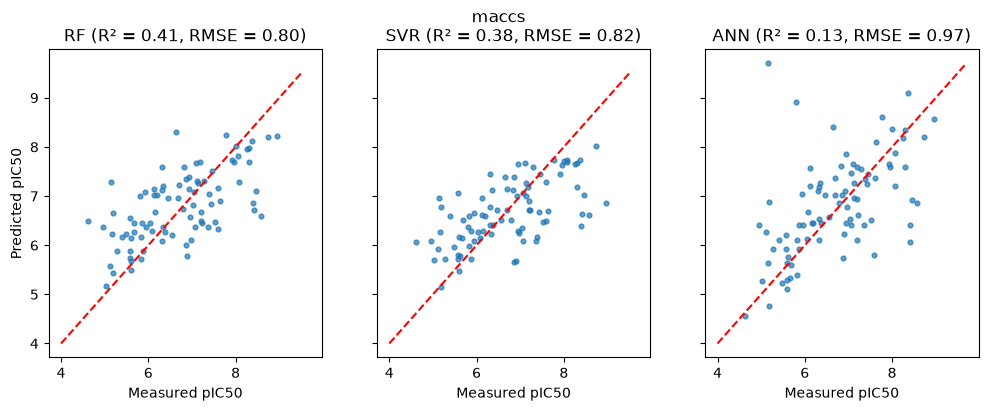

morgan2: X = (435, 2048), pIC50 range = 4.00-9.52


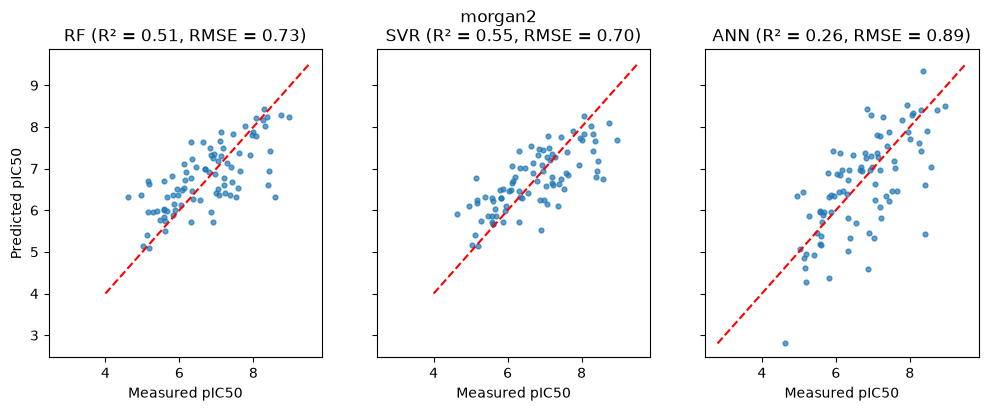

morgan3: X = (435, 2048), pIC50 range = 4.00-9.52


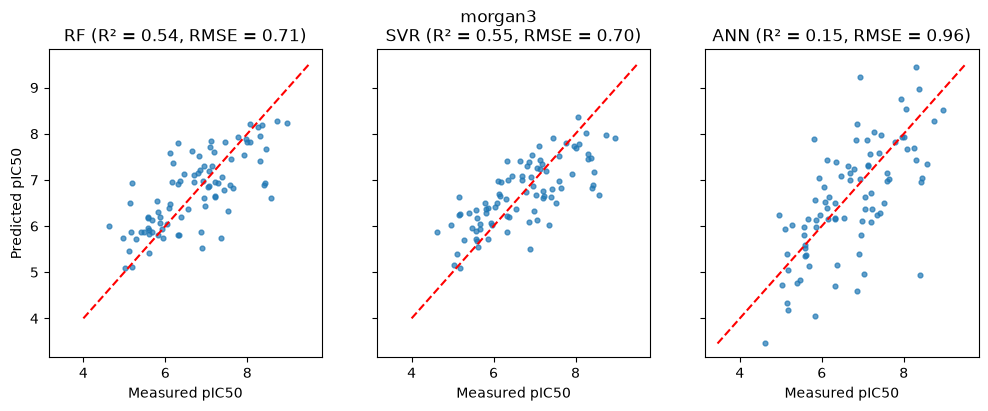

In [6]:
split_rows, cv_rows = [], []
for method in FINGERPRINTS:
    X, y = load_fingerprint_data(method)
    print(f"{method}: X = {X.shape}, pIC50 range = {y.min():.2f}-{y.max():.2f}")
    split_rows += single_split_evaluation(method, X, y)
    cv_rows += crossvalidation(method, X, y)

split_df = pd.DataFrame(split_rows)
cv_df = pd.DataFrame(cv_rows)
split_df.to_csv(OUT_DIR / "reg_results_single_split.csv", index=False)
cv_df.to_csv(OUT_DIR / "reg_results_crossvalidation.csv", index=False)

In [7]:
print("Single train/test split")
split_df.round(2)

Single train/test split


,fingerprint,model,rmse,mae,r2,pearson_r
0,maccs,RF,0.80,0.63,0.41,0.65
1,maccs,SVR,0.82,0.64,0.38,0.62
2,maccs,ANN,0.97,0.66,0.13,0.56
3,morgan2,RF,0.73,0.58,0.51,0.72
4,morgan2,SVR,0.70,0.56,0.55,0.74
5,morgan2,ANN,0.89,0.70,0.26,0.69
6,morgan3,RF,0.71,0.55,0.54,0.73
7,morgan3,SVR,0.70,0.57,0.55,0.74
8,morgan3,ANN,0.96,0.74,0.15,0.67


In [8]:
print(f"{N_FOLDS}-fold cross-validation")
cv_df.round(2)

5-fold cross-validation


,fingerprint,model,rmse_mean,rmse_std,mae_mean,mae_std,r2_mean,r2_std,pearson_r_mean,pearson_r_std,time_s
0,maccs,RF,0.86,0.06,0.67,0.04,0.37,0.06,0.62,0.04,0.68
1,maccs,SVR,0.87,0.04,0.66,0.04,0.35,0.03,0.61,0.01,0.03
2,maccs,ANN,1.03,0.08,0.75,0.06,0.08,0.15,0.52,0.08,1.28
3,morgan2,RF,0.77,0.06,0.60,0.05,0.49,0.07,0.71,0.04,3.20
4,morgan2,SVR,0.76,0.06,0.59,0.05,0.51,0.06,0.72,0.04,0.21
5,morgan2,ANN,1.03,0.09,0.79,0.07,0.09,0.14,0.63,0.05,3.20
6,morgan3,RF,0.76,0.06,0.59,0.06,0.50,0.06,0.71,0.05,4.57
7,morgan3,SVR,0.76,0.06,0.60,0.05,0.51,0.06,0.72,0.05,0.21
8,morgan3,ANN,1.12,0.11,0.84,0.06,-0.08,0.25,0.59,0.08,2.69


## Final model for prediction on new datasets

The evaluation above fits a new model for every split and fold and throws it away afterwards.
To predict new compounds, we pick the best combination from the cross-validation
(highest R², lowest RMSE), fit it once on **all** compounds, and save it to disk.

In [9]:
# Best combination in the cross-validation above (highest R², lowest RMSE)
FINAL_MODEL = "SVR"
FINAL_FINGERPRINT = "morgan2"
FINAL_MODEL_PATH = OUT_DIR / f"final_{FINAL_MODEL.lower()}_{FINAL_FINGERPRINT}.joblib"

In [10]:
def train_final_model():
    """Fit the chosen model on ALL compounds (no split) and save it to disk."""
    X, y = load_fingerprint_data(FINAL_FINGERPRINT)
    model = get_models()[FINAL_MODEL].fit(X, y)
    joblib.dump(model, FINAL_MODEL_PATH)
    print(f"Final {FINAL_MODEL} ({FINAL_FINGERPRINT}) fit on {len(y)} compounds -> {FINAL_MODEL_PATH}")
    return model


final_model = train_final_model()

Final SVR (morgan2) fit on 435 compounds -> /Users/bartrabelink/Desktop/ACMDD group 6 assignment/ACMDD_D2_Receptor/data/final_svr_morgan2.joblib


## Predict pIC50 for a new dataset (no retraining)

`predict_pic50` loads the saved model and encodes the new SMILES with the **same**
fingerprint as the training data. Once the model is saved, only the settings cell,
the imports and this cell are needed to predict a new dataset.

In [11]:
def predict_pic50(smiles_list, model_path=FINAL_MODEL_PATH):
    """Predict pIC50 and IC50 (nM) for new SMILES with the saved model (no retraining)."""
    model = joblib.load(model_path)
    rows = []
    for smi in smiles_list:
        fp = smiles_to_fp(smi, FINAL_FINGERPRINT)  # same featurisation as the training data
        if fp is None:  # SMILES RDKit cannot parse
            rows.append({"smiles": smi, "pred_pIC50": np.nan, "pred_IC50_nM": np.nan})
            continue
        if FINAL_FINGERPRINT == "maccs":
            fp = fp[1:]  # training data dropped MACCS bit 0
        pic50 = model.predict(fp.reshape(1, -1).astype(float))[0]
        rows.append({"smiles": smi, "pred_pIC50": pic50, "pred_IC50_nM": 10 ** (9 - pic50)})
    return pd.DataFrame(rows)

In [12]:
# Example: predict a few SMILES. For a dataset, use e.g.
# new_df = pd.read_csv("path/to/new_dataset.csv")
# predictions = predict_pic50(new_df["smiles"])
example_smiles = [
    "OCCN1CCN(CCCN2c3ccccc3Sc3ccc(Cl)cc32)CC1",                # CHEMBL567, measured pIC50 9.52
    "CC1=C(C(=O)N2CCCCC2=N1)CCN3CCN(CC3)C4=CC=CC5=C4C=CN5",    # similarity-search hit
]
predict_pic50(example_smiles)

,smiles,pred_pIC50,pred_IC50_nM
0,OCCN1CCN(CCCN2c3ccccc3Sc3ccc(Cl)cc32)CC1,8.097969,7.980516
1,CC1=C(C(=O)N2CCCCC2=N1)CCN3CCN(CC3)C4=CC=CC5=C...,7.784896,16.409822
